<a href="https://colab.research.google.com/github/onethinghseu/QML-Hackathon/blob/main/QML_Hackathon.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install matminer
!pip install pennylane

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 29.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 17.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 829.7/829.7 kB 16.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.7/4.7 MB 56.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 44.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 979.1/979.1 kB 38.8 MB/s  0:00:00
  Created wheel for bibtexparser: filename=bibtexparser-1.4.4-py3-none-any.whl size=43686 sha256=892edd7a1b2845d0ae2f3315b5cf5fd5e1a9d85b775b6a15a14867580934fbba
  Stored in directory: /root/.cache/pip/wheels/43/ca/d8/0d315657fcf8ff8694a2f6701589bd1eaa602a85b7a7810063
Successfully built bibtexparser
  Attempting uninstall: scipy
    Found existing installation: scipy 1.16.3
    Uninstalling scipy-1.16.3:
   

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matminer.datasets import load_dataset

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, r2_score

import pennylane as qml
from scipy.optimize import minimize

In [ ]:
df = load_dataset("matbench_perovskites")

print("Dataset shape:", df.shape)
display(df.head())

Fetching matbench_perovskites.json.gz from https://ml.materialsproject.org/projects/matbench_perovskites.json.gz to /usr/local/lib/python3.13/dist-packages/matminer/datasets/matbench_perovskites.json.gz


Fetching https://ml.materialsproject.org/projects/matbench_perovskites.json.gz in MB: 4.194304MB [00:00, 494.29MB/s]                


Dataset shape: (18928, 2)


,structure,e_form
0,"[[0. 0. 0.] Rh, [1.97726555 1.97726555 1.97726...",2.16
1,"[[2.54041798 0. 0. ] Hf, [1.020...",1.52
2,"[[0.60790913 0. 0. ] Re, [2.186...",1.48
3,"[[2.83091357 0. 0. ] W, [2.6573...",1.24
4,"[[0.00518937 0. 0. ] Bi, [2.172...",0.62


In [ ]:
print("Columns:", df.columns.tolist())
print("\nMissing values:")
print(df.isnull().sum())

print("\nFormation energy statistics:")
print(df["e_form"].describe())

Columns: ['structure', 'e_form']

Missing values:
structure    0
e_form       0
dtype: int64

Formation energy statistics:
count    18928.000000
mean         1.470932
std          0.742502
min         -0.640000
25%          0.960000
50%          1.360000
75%          1.840000
max          5.160000
Name: e_form, dtype: float64


In [ ]:
structure = df.iloc[0]["structure"]

print("Composition:", structure.composition)
print("Atomic numbers:", [site.specie.Z for site in structure])
print("Electronegativity:", [site.specie.X for site in structure])
print("Lattice parameters:", structure.lattice.abc)
print("Lattice angles:", structure.lattice.angles)
print("Unit-cell volume:", structure.volume)
print("Density:", structure.density)
print("Atomic positions:", structure.cart_coords)

Composition: Rh1 Te1 N3
Atomic numbers: [45, 52, 7, 7, 7]
Electronegativity: [2.28, 2.1, 3.04, 3.04, 3.04]
Lattice parameters: (3.9545311067746507, 3.9545311067746507, 3.9545311067746507)
Lattice angles: (90.0, 90.0, 90.0)
Unit-cell volume: 61.842208164886245
Density: 7.317646305162406 g cm^-3
Atomic positions: [[0.         0.         0.        ]
 [1.97726555 1.97726555 1.97726555]
 [1.97726555 0.         1.97726555]
 [1.97726555 1.97726555 0.        ]
 [0.         1.97726555 1.97726555]]


In [ ]:

print(df.shape)
print(df.columns)
print(df.isnull().sum())

# Select 1000 structures for our prototype
df_small = df.sample(n=1000, random_state=42).copy()

display(df_small.head())

(18928, 2)
Index(['structure', 'e_form'], dtype='object')
structure    0
e_form       0
dtype: int64


,structure,e_form
1705,[[5.41058496e-01 4.80898524e+00 1.05421231e-16...,0.94
6508,[[7.03189378e-01 2.95042394e-16 2.79319491e-16...,0.78
11429,"[[0.00012026 0. 0. ] Hg, [2.757...",2.86
14316,[[1.75390043e+00 1.25293590e-14 4.17249992e+00...,0.76
12412,[[1.15136204e+00 0.00000000e+00 5.17907560e-17...,1.72


In [ ]:
def extract_features(structure):
    elements = [site.specie for site in structure]

    atomic_numbers = [el.Z for el in elements]
    electronegativities = [el.X for el in elements]
    atomic_radii = [
        float(el.atomic_radius) if el.atomic_radius is not None else np.nan
        for el in elements
    ]

    lattice = structure.lattice

    distances = []
    for i in range(len(structure)):
        neighbors = structure.get_neighbors(structure[i], 5.0)
        if neighbors:
            distances.append(min(n.nn_distance for n in neighbors))

    return {
        "mean_atomic_number": np.mean(atomic_numbers),
        "mean_electronegativity": np.mean(electronegativities),
        "mean_atomic_radius": np.nanmean(atomic_radii),
        "lattice_a": lattice.a,
        "lattice_b": lattice.b,
        "lattice_c": lattice.c,
        "angle_alpha": lattice.alpha,
        "angle_beta": lattice.beta,
        "angle_gamma": lattice.gamma,
        "volume": structure.volume,
        "density": structure.density,
        "mean_nearest_neighbor_distance": np.mean(distances) if distances else np.nan
    }

features = pd.DataFrame(
    [extract_features(s) for s in df_small["structure"]],
    index=df_small.index
)

display(features.head())

,mean_atomic_number,mean_electronegativity,mean_atomic_radius,lattice_a,lattice_b,lattice_c,angle_alpha,angle_beta,angle_gamma,volume,density,mean_nearest_neighbor_distance
1705,33.6,2.620,1.10,4.808985,4.808985,4.808985,90.0,90.0,90.0,111.214223,5.971440,2.349406
6508,17.2,2.698,0.91,3.873754,3.873754,3.873754,90.0,90.0,90.0,58.129443,5.476062,1.957394
11429,29.8,2.456,1.21,5.443114,5.443114,5.443114,90.0,90.0,90.0,161.265809,3.605170,2.941904
14316,17.0,2.638,0.96,4.172500,4.172500,4.172500,90.0,90.0,90.0,72.642204,4.320848,2.088318
12412,10.8,2.758,0.82,3.655467,3.655467,3.655467,90.0,90.0,90.0,48.845961,3.829975,1.759981


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, r2_score

X = features.replace([np.inf, -np.inf], np.nan)
y = df_small["e_form"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

imputer = SimpleImputer(strategy="median")

X_train_clean = imputer.fit_transform(X_train)
X_test_clean = imputer.transform(X_test)

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train_clean, y_train)

predictions = model.predict(X_test_clean)

Model trained successfully!


In [ ]:
mae = mean_absolute_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

print("Mean Absolute Error:", mae)
print("R² Score:", r2)

Mean Absolute Error: 0.526262
R² Score: 0.3061011997491825


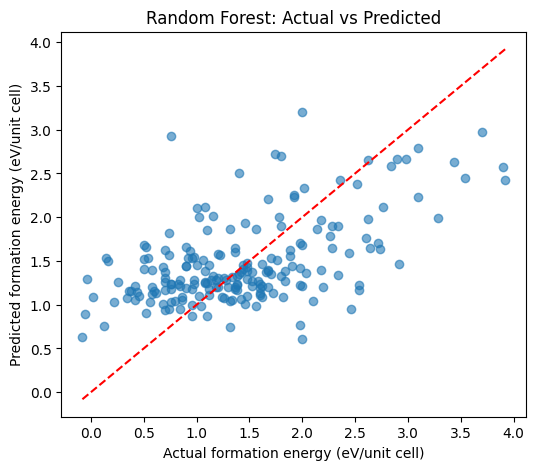

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))
plt.scatter(y_test, predictions, alpha=0.6)

low = min(y_test.min(), predictions.min())
high = max(y_test.max(), predictions.max())

plt.plot([low, high], [low, high], "r--")

plt.xlabel("Actual formation energy (eV/unit cell)")
plt.ylabel("Predicted formation energy (eV/unit cell)")
plt.title("Random Forest: Actual vs Predicted")
plt.show()

In [ ]:
results = df_small.loc[X_test.index, ["structure", "e_form"]].copy()

results["predicted_energy"] = predictions

results["formula"] = results["structure"].apply(
    lambda s: s.composition.reduced_formula
)

results = results.sort_values("predicted_energy")

display(
    results[
        ["formula", "predicted_energy", "e_form"]
    ].head(10)
)

,formula,predicted_energy,e_form
8494,CsBeNOF,0.6030,2.00
3848,BaMnO3,0.6358,-0.08
11890,ZnNiO3,0.7502,1.32
8375,MnPbO2F,0.7550,0.12
18794,SrPdN3,0.7652,1.98
12416,InCoNOF,0.8672,0.96
18376,BaAsN2O,0.8758,1.10
15928,BaCrO2F,0.8930,-0.06
1804,TaInN2O,0.9038,0.52
14917,YNbSO2,0.9422,0.70


In [ ]:
%pip install -q pennylane scipy

In [ ]:
import pennylane as qml

H = (
    -1.0 * qml.PauliZ(0)
    -0.5 * qml.PauliZ(1)
    +0.3 * (qml.PauliX(0) @ qml.PauliX(1))
)

print(H)

-1.0 * Z(0) + -0.5 * Z(1) + 0.3 * (X(0) @ X(1))


In [ ]:
from scipy.optimize import minimize

dev = qml.device("default.qubit", wires=2)

@qml.qnode(dev)
def energy(params):
    qml.RY(params[0], wires=0)
    qml.RY(params[1], wires=1)

    qml.CNOT(wires=[0, 1])

    qml.RY(params[2], wires=0)
    qml.RY(params[3], wires=1)

    return qml.expval(H)

history = []

def objective(params):
    value = float(energy(params))
    history.append(value)
    return value

initial_params = np.array([0.1, 0.2, 0.3, 0.4])

result = minimize(
    objective,
    initial_params,
    method="COBYLA",
    options={"maxiter": 300}
)

print("VQE estimated ground-state energy:", result.fun)
print("Optimization successful:", result.success)

VQE estimated ground-state energy: -1.5297058505512757
Optimization successful: True


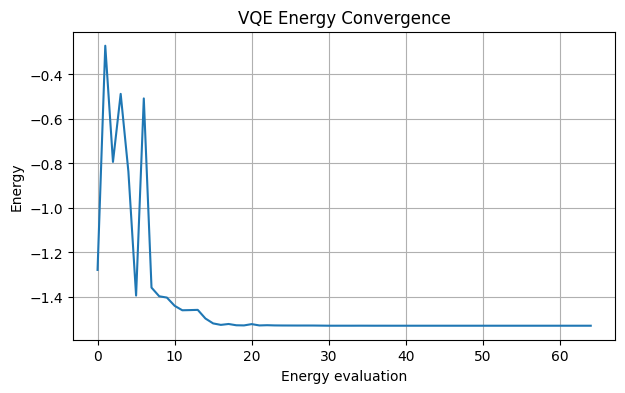

In [ ]:
plt.figure(figsize=(7, 4))

plt.plot(history)
plt.xlabel("Energy evaluation")
plt.ylabel("Energy")
plt.title("VQE Energy Convergence")
plt.grid(True)

plt.show()

In [ ]:
H_matrix = qml.matrix(H, wire_order=[0, 1])

exact_energy = np.linalg.eigvalsh(H_matrix)[0]

print("Exact ground-state energy:", exact_energy)
print("VQE estimated energy:", result.fun)
print("Absolute error:", abs(result.fun - exact_energy))

Exact ground-state energy: -1.5297058540778354
VQE estimated energy: -1.5297058505512757
Absolute error: 3.5265597109201963e-09


Data Guided Quantum energy estimation for perovskite materials

Can structural information from perovskite crystals guide quantum ground-state energy estimation using a simplified Hamiltonian?

In [ ]:
# imports
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# calculating distance
def mean_nearest_neighbor_distance(structure):
    distances = []

    for i in range(len(structure)):
        neighbors = structure.get_neighbors(structure[i], 5.0)

        if neighbors:
            nearest = min(n.nn_distance for n in neighbors)
            distances.append(nearest)

    return np.mean(distances) if distances else np.nan

# Use a subset for quick exploration
df_small = df.sample(n=1000, random_state=42).copy()

df_small["mean_nn_distance"] = df_small["structure"].apply(
    mean_nearest_neighbor_distance
)

display(df_small[["mean_nn_distance", "e_form"]].head())

,mean_nn_distance,e_form
1705,2.349406,0.94
6508,1.957394,0.78
11429,2.941904,2.86
14316,2.088318,0.76
12412,1.759981,1.72


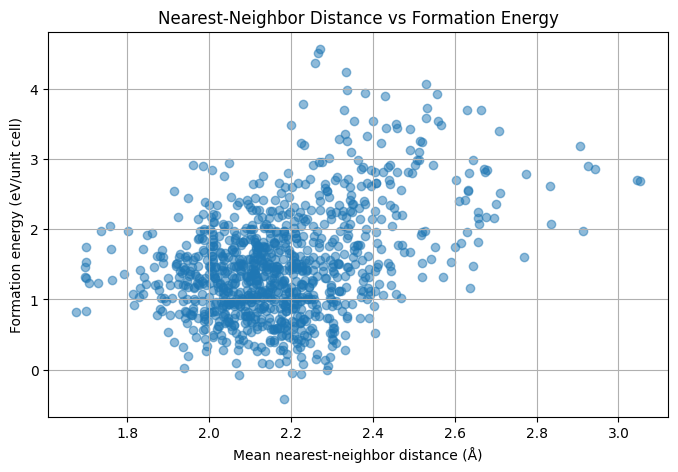

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df_small["mean_nn_distance"],
    df_small["e_form"],
    alpha=0.5
)

plt.xlabel("Mean nearest-neighbor distance (Å)")
plt.ylabel("Formation energy (eV/unit cell)")
plt.title("Nearest-Neighbor Distance vs Formation Energy")
plt.grid(True)
plt.show()

Formation energy cannot be reliably determined from a single geometric descriptor because it also depends on chemical composition and more complex atomic interactions.

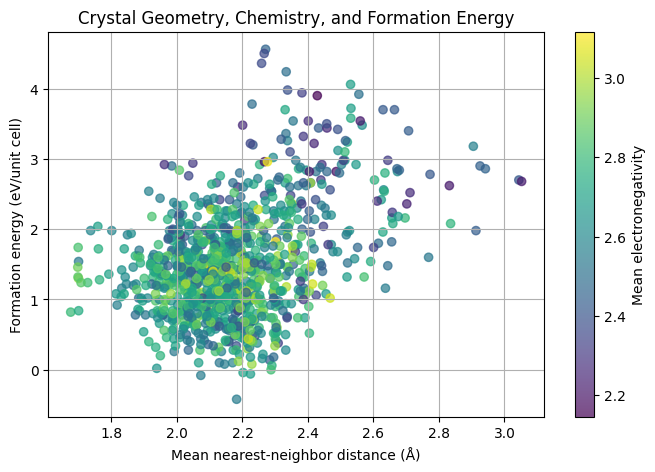

In [ ]:
def mean_electronegativity(structure):
    values = [site.specie.X for site in structure]
    return np.mean(values)

df_small["mean_electronegativity"] = df_small["structure"].apply(
    mean_electronegativity
)

plt.figure(figsize=(8, 5))

scatter = plt.scatter(
    df_small["mean_nn_distance"],
    df_small["e_form"],
    c=df_small["mean_electronegativity"],
    cmap="viridis",
    alpha=0.7
)

plt.colorbar(scatter, label="Mean electronegativity")
plt.xlabel("Mean nearest-neighbor distance (Å)")
plt.ylabel("Formation energy (eV/unit cell)")
plt.title("Crystal Geometry, Chemistry, and Formation Energy")
plt.grid(True)
plt.show()

Three random forest models

In [ ]:
# Function to extract numerical features from a crystal structure
def extract_features(structure):

    # Get the elements present at each atomic site
    elements = [site.specie for site in structure]

    # Extract atomic numbers
    atomic_numbers = [el.Z for el in elements]

    # Extract electronegativity values
    electronegativities = [el.X for el in elements]

    # Extract atomic radii
    # Use NaN if an atomic radius is unavailable
    atomic_radii = [
        float(el.atomic_radius) if el.atomic_radius is not None else np.nan
        for el in elements
    ]

    # Calculate chemical and structural descriptors
    return {
        # Chemical features
        "mean_atomic_number": np.mean(atomic_numbers),
        "mean_electronegativity": np.mean(electronegativities),
        "electronegativity_difference": np.ptp(electronegativities),
        "mean_atomic_radius": np.nanmean(atomic_radii),

        # Structural features
        "lattice_a": structure.lattice.a,
        "lattice_b": structure.lattice.b,
        "lattice_c": structure.lattice.c,
        "volume": structure.volume,
        "density": structure.density
    }


# Extract features from every crystal in our selected dataset
features = pd.DataFrame(
    [extract_features(s) for s in df_small["structure"]],
    index=df_small.index
)

# Add the nearest-neighbor distances calculated previously
features["mean_nn_distance"] = df_small["mean_nn_distance"]

# Display the first five rows of extracted features
display(features.head())

,mean_atomic_number,mean_electronegativity,electronegativity_difference,mean_atomic_radius,lattice_a,lattice_b,lattice_c,volume,density,mean_nn_distance
1705,33.6,2.620,2.34,1.10,4.808985,4.808985,4.808985,111.214223,5.971440,2.349406
6508,17.2,2.698,1.83,0.91,3.873754,3.873754,3.873754,58.129443,5.476062,1.957394
11429,29.8,2.456,2.62,1.21,5.443114,5.443114,5.443114,161.265809,3.605170,2.941904
14316,17.0,2.638,2.13,0.96,4.172500,4.172500,4.172500,72.642204,4.320848,2.088318
12412,10.8,2.758,1.61,0.82,3.655467,3.655467,3.655467,48.845961,3.829975,1.759981


In [ ]:
# Structural features describe the geometry of the crystal
structural_features = [
    "lattice_a",
    "lattice_b",
    "lattice_c",
    "volume",
    "mean_nn_distance"
]

# Chemical features describe the atomic properties
chemical_features = [
    "mean_atomic_number",
    "mean_electronegativity",
    "electronegativity_difference",
    "mean_atomic_radius"
]

# Combine both groups for our third ML model
combined_features = structural_features + chemical_features

# Display the number of features in each group
print("Structural features:", len(structural_features))
print("Chemical features:", len(chemical_features))
print("Combined features:", len(combined_features))

# Check for missing values before training
print("\nMissing values:")
print(features[combined_features].isnull().sum())

Structural features: 5
Chemical features: 4
Combined features: 9

Missing values:
lattice_a                       0
lattice_b                       0
lattice_c                       0
volume                          0
mean_nn_distance                0
mean_atomic_number              0
mean_electronegativity          0
electronegativity_difference    0
mean_atomic_radius              0
dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Target variable: formation energy
y = df_small["e_form"]

# Split row indices so all models use the same crystals
train_idx, test_idx = train_test_split(
    features.index,
    test_size=0.2,
    random_state=42
)

# Define the three feature groups
feature_groups = {
    "Structural": structural_features,
    "Chemical": chemical_features,
    "Combined": combined_features
}

# Store trained models and their evaluation results
models = {}
results = []

In [ ]:
# Train a separate Random Forest for each feature group
for name, columns in feature_groups.items():

    # Select the corresponding features
    X_train = features.loc[train_idx, columns]
    X_test = features.loc[test_idx, columns]

    # Select the corresponding formation energies
    y_train = y.loc[train_idx]
    y_test = y.loc[test_idx]

    # Initialize the Random Forest regressor
    model = RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )

    # Train the model
    model.fit(X_train, y_train)

    # Predict formation energies for unseen test crystals
    predictions = model.predict(X_test)

    # Calculate prediction accuracy
    mae = mean_absolute_error(y_test, predictions)
    r2 = r2_score(y_test, predictions)

    # Save the trained model
    models[name] = model

    # Save evaluation metrics
    results.append({
        "Model": name,
        "MAE": mae,
        "R2": r2
    })

# Display comparison table
comparison_df = pd.DataFrame(results)

display(comparison_df)

,Model,MAE,R2
0,Structural,0.616910,0.016876
1,Chemical,0.574136,0.158818
2,Combined,0.478056,0.393660
